# 🕸️ Sesión 1: El ADN de las Redes
Representación de Grafos: Matriz vs Lista de Adyacencia.

## 📐 Formalización Matemática: ¿Qué es un Grafo?

Un grafo es una estructura matemática que modela relaciones entre objetos. Formalmente se define como un par ordenado:

$$G = (V, E)$$

Donde:
*   **$V$ (Vértices / Nodos):** Es el conjunto de entidades que conforman la red. En nuestro ejemplo del pizarrón, $V = \{\text{Ana, Carlos, Luis, Beti}\}$.
*   **$E$ (Aristas / Edges):** Es el conjunto de conexiones (pares de vértices). Si Ana sigue a Carlos, existe una arista $e = (Ana, Carlos)$.

---
### Tipos de Relaciones

1.  **Grafo Dirigido (DiGraph):** Las aristas tienen dirección (flechas). Si $(u, v) \in E$, no implica necesariamente que $(v, u) \in E$. *(Ejemplo: Seguir a alguien en Instagram, transferencias bancarias).* 
2.  **Grafo No Dirigido (Graph):** Las relaciones son recíprocas. La arista $(u, v)$ es idéntica a $(v, u)$. *(Ejemplo: Ser amigos en Facebook, conexiones Bluetooth).* 
3.  **Grafo Ponderado (Weighted Graph):** Cada arista tiene un peso o costo numérico $w(u,v)$. *(Ejemplo: La distancia en kilómetros entre dos aeropuertos, la cantidad de mensajes entre dos usuarios).*

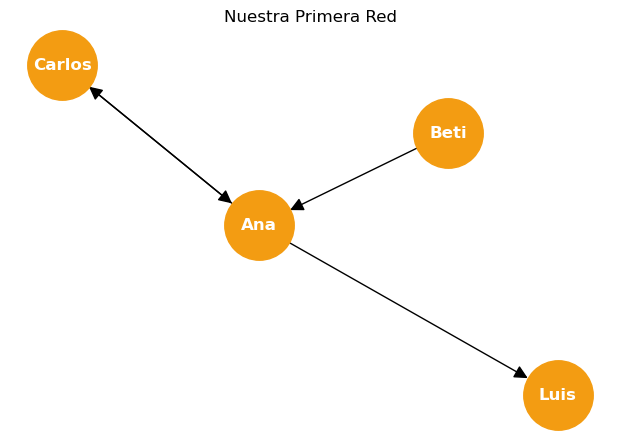

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

G = nx.DiGraph()
G.add_edges_from([('Ana', 'Carlos'), ('Carlos', 'Ana'), ('Ana', 'Luis'), ('Beti', 'Ana')])

# 2. Dibujar el Grafo
plt.figure(figsize=(6,4))
nx.draw(G, with_labels=True, node_color='#F39C12', node_size=2500, font_weight='bold', font_color='white', arrowsize=20)
plt.title('Nuestra Primera Red')
plt.show()

### ⚠️ El colapso en la RAM: La Matriz de Adyacencia
Fácil de leer para las matemáticas, terrible para la memoria de la computadora en Big Data.

In [2]:
matriz = nx.adjacency_matrix(G).todense()
print("Nodos en orden:", G.nodes())
print("\nMatriz de Adyacencia:")
print(matriz)

Nodos en orden: ['Ana', 'Carlos', 'Luis', 'Beti']

Matriz de Adyacencia:
[[0 1 1 0]
 [1 0 0 0]
 [0 0 0 0]
 [1 0 0 0]]


### 🚀 La Salvación: Lista de Aristas (Edge List)
Solo guardamos las conexiones que SÍ existen.

In [3]:
print("Lista de Aristas (Edge List):")
for edge in G.edges():
    print(f"{edge[0]} ---> {edge[1]}")

Lista de Aristas (Edge List):
Ana ---> Carlos
Ana ---> Luis
Carlos ---> Ana
Beti ---> Ana


# El Analista de Vuelos y el Choque de Memoria
Contexto del Negocio: Ustedes son los Ingenieros de Datos de una alianza global de aerolíneas. Les han entregado el archivo vuelos_10k.csv extraído directamente de los servidores antiguos de la torre de control. Su objetivo final es modelar la red de rutas aéreas utilizando Teoría de Grafos (networkx), pero el sistema advierte que el archivo está lleno de errores de captura.

In [4]:

df = pd.read_csv("../datasets/vuelos_10k.csv")
print( df.head(5))

  Origen Destino  Distancia_km
0    RYI     KXK        965.34
1    ULE     PVC       1098.58
2    LTV     MOV       2713.63
3    NFR     CLR       1138.99
4    TSF     CZE       1691.08


# 🧹 Fase 1: Limpieza Estructural (Data Cleaning)
Antes de construir el grafo, deben usar pandas y las técnicas que vimos en la Unidad I y II para purificar la tabla.

Valores Nulos: Encuentren y eliminen cualquier registro que no tenga Origen o Destino.
Formato Inconsistente: El código del aeropuerto siempre debe ser de 3 letras mayúsculas (Ej. "MEX"). Arreglen las filas que estén en minúsculas.
Anomalías Lógicas (Self-Loops): Un avión no puede despegar de un aeropuerto y aterrizar en ese mismo aeropuerto. ¿Qué debemos hacer con esos registros?
Errores de Captura: La distancia no puede ser un número negativo, corrijan esos errores.
Duplicados: Para modelar la red, solo necesitamos saber si existe la ruta. Eliminen las filas duplicadas (mismo origen y mismo destino)

In [5]:
print(df.count())

# drop null values
df_cleaned = df.dropna().copy()
print("Drop values \n",df_cleaned.count())

# uppercase (antes de buscar self-loops y duplicados, para que "mex" == "MEX")
df_cleaned["Origen"] = df_cleaned["Origen"].str.strip().str.upper()
df_cleaned["Destino"] = df_cleaned["Destino"].str.strip().str.upper()

# remove self loops
df_cleaned = df_cleaned[df_cleaned["Origen"] != df_cleaned["Destino"]]
print("Remove self loops \n",df_cleaned.count())

# fix negative distances (error de captura del signo -> valor absoluto)
print("Distancias negativas:", (df_cleaned["Distancia_km"] < 0).sum())
df_cleaned["Distancia_km"] = df_cleaned["Distancia_km"].abs()

# Remove duplicate routes
df_cleaned = df_cleaned.drop_duplicates(subset=["Origen","Destino"])
print("Remove duplicates \n",df_cleaned.count())

Origen           9949
Destino          9900
Distancia_km    10000
dtype: int64
Drop values 
 Origen          9849
Destino         9849
Distancia_km    9849
dtype: int64
Remove self loops 
 Origen          9744
Destino         9744
Distancia_km    9744
dtype: int64
Distancias negativas: 100
Remove duplicates 
 Origen          9743
Destino         9743
Distancia_km    9743
dtype: int64


# 🕸️ Fase 2: Extracción de la Red
Con su DataFrame perfectamente limpio (que actúa como una Lista de Aristas o Edge List):

Importen la librería networkx.
- Utilicen la función nx.from_pandas_edgelist() para convertir su DataFrame en un Grafo Dirigido (nx.DiGraph).
- Impriman en pantalla cuántos Nodos (Aeropuertos) y cuántas Aristas (Rutas) tiene su grafo final.

In [6]:
G = nx.from_pandas_edgelist(
    df_cleaned,
    source="Origen",
    target="Destino",
    create_using=nx.DiGraph()
    )

print("Number of nodes: ", G.number_of_nodes())
print("Number of edges: ", G.number_of_edges())

Number of nodes:  3253
Number of edges:  9743


# 💥 Fase 3: El Experimento de la Memoria RAM
¡Llegó la hora de comprobar la teoría de la clase!

Construyan la Matriz de Adyacencia densa a partir de su grafo usando nx.adjacency_matrix(G).todense().
Utilicen código Python (ej. el atributo .nbytes) para calcular cuántos Megabytes (MB) de Memoria RAM está consumiendo su Matriz de Adyacencia llena de ceros.
Calculen cuántos Megabytes está consumiendo su DataFrame limpio (la Lista de Aristas).
Veredicto: Añadan una celda Markdown al final de su notebook respondiendo: ¿Cuántas veces más pesada es la Matriz en comparación con la Lista de Aristas y por qué sucede esto?

In [7]:
matriz_densa = nx.adjacency_matrix(G).todense()

mb_matriz = matriz_densa.nbytes / 1024**2
mb_lista = df_cleaned.memory_usage(deep=True).sum() / 1024**2

n, m = G.number_of_nodes(), G.number_of_edges()
densidad = m / (n * n)

print(f"Forma de la matriz: {matriz_densa.shape}  ({n*n:,} celdas, dtype={matriz_densa.dtype})")
print(f"Celdas con 1: {m:,}  ->  densidad = {densidad:.4%}  (ceros: {1 - densidad:.4%})")
print(f"\nMemoria Matriz de Adyacencia: {mb_matriz:,.2f} MB")
print(f"Memoria Lista de Aristas (DataFrame): {mb_lista:,.2f} MB")
print(f"\nLa matriz es {mb_matriz / mb_lista:,.1f} veces más pesada")

Forma de la matriz: (3253, 3253)  (10,582,009 celdas, dtype=int64)
Celdas con 1: 9,743  ->  densidad = 0.0921%  (ceros: 99.9079%)

Memoria Matriz de Adyacencia: 80.73 MB
Memoria Lista de Aristas (DataFrame): 1.26 MB

La matriz es 63.9 veces más pesada



**La Matriz de Adyacencia es ~64 veces más pesada** que la Lista de Aristas: **80.73 MB** contra **1.26 MB**.

**¿Por qué?**

- **La matriz crece con el cuadrado de los nodos ($O(|V|^2)$).** Con 3,253 aeropuertos, la matriz necesita $3253^2 = 10{,}582{,}009$ celdas, y cada una ocupa 8 bytes (`int64`). Reserva espacio para **todas las rutas posibles**, existan o no.
- **La lista de aristas crece con las conexiones reales ($O(|E|)$).** Solo guarda las 9,743 rutas que sí existen (origen, destino, distancia).
- **La red es extremadamente dispersa (*sparse*).** Solo el **0.09 %** de las celdas tiene un 1. El **99.91 %** de la memoria de la matriz se gasta en guardar ceros, es decir, rutas que no existen.

La diferencia empeora con la escala: si duplicamos los aeropuertos, la matriz pesa **4 veces más**, mientras que la lista solo crece en proporción a las rutas nuevas. Por eso, en Big Data los grafos se almacenan como listas de aristas/adyacencia o matrices *sparse* (`nx.adjacency_matrix(G)` sin `.todense()` devuelve una matriz `scipy.sparse` que solo guarda los valores distintos de cero).